# What are the GitSkills skills for?

This notebook inspects purpose clustering of the same 11,015 distinct contents. Proposed labels are assistant interpretations of terms and sampled descriptions, not human-validated ground truth. The interactive artifact is `artifacts/gitskills-purpose-explorer.html`.


In [1]:
import csv, html, json, subprocess, sys
from pathlib import Path
from IPython.display import display, HTML, Image, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "gitskills").is_dir())
OUT = ROOT / "results" / "purpose"
def rows(name):
    with (OUT / name).open(encoding="utf-8", newline="") as stream:
        return list(csv.DictReader(stream))
def table(items, fields):
    head = "".join("<th>" + html.escape(field) + "</th>" for field in fields)
    body = "".join("<tr>" + "".join("<td>" + html.escape(str(item.get(field, ""))) + "</td>" for field in fields) + "</tr>" for item in items)
    display(HTML("<table><tr>" + head + "</tr>" + body + "</table>"))
summary = json.loads((OUT / "summary.json").read_text())


Names/descriptions and body text receive separate TF-IDF views, weighted 85% and 15% before 128-dimensional LSA and K-means. There are 24 clusters for inspection; this is not a claim that the corpus has exactly 24 real purposes. Reproduce with `.venv/bin/python -m gitskills.purpose --output results/purpose-reproduction`.


cluster,purpose,contents,assessment
0,Mixed purposes / multilingual residual,1800,unresolved
1,Application development and framework patterns,719,broad
2,"Operating apps, messaging and personal tools",662,broad
3,"Deployment, cloud infrastructure and operations",634,broad
4,"Business strategy, sales and finance",617,broad
5,"Requirements, specifications and implementation planning",586,focused
6,Project documentation and repository setup,576,broad
7,"Code understanding, quality and refactoring",458,broad
8,Machine learning and scientific analysis,448,broad
9,"Git, commits, pull requests and releases",424,focused


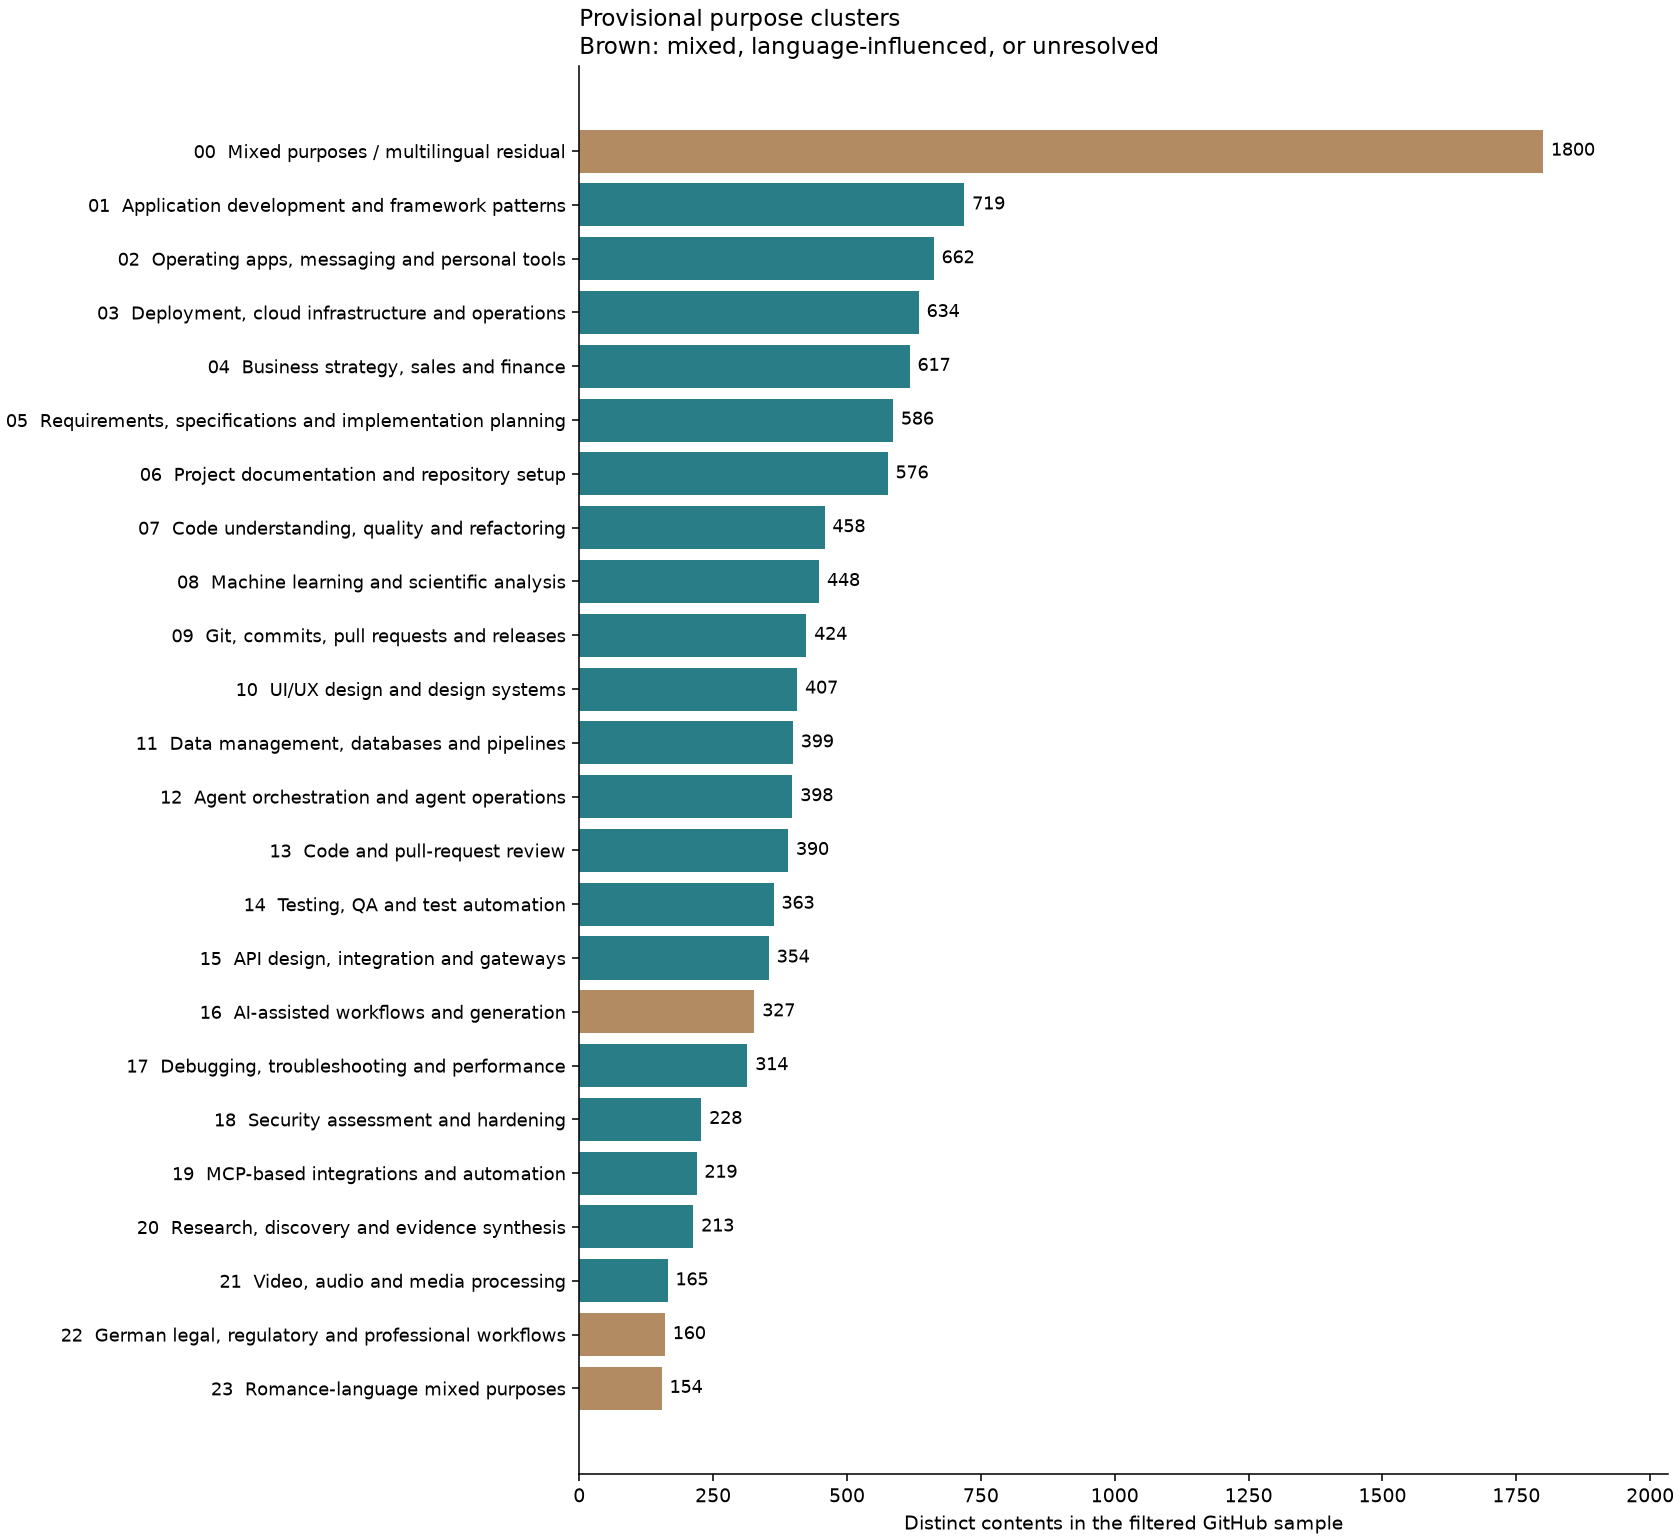

In [2]:
table(rows("purpose_summary.csv"), ["cluster", "purpose", "contents", "assessment"])
display(Image(filename=str(OUT / "purpose_clusters.png")))


Check separation, initialization sensitivity and text-view sensitivity before interpreting the group labels. Low margins are geometric uncertainty flags, not calibrated confidence. Scores below show that this initial taxonomy needs refinement.


In [3]:
table(rows("cluster_count_comparison.csv"), ["clusters", "silhouette_cosine", "davies_bouldin", "smallest_cluster", "largest_cluster"])
table(rows("seed_stability.csv"), ["seed", "adjusted_rand_vs_main"])
table(rows("view_comparison.csv"), ["view", "adjusted_rand_vs_main", "aligned_assignment_agreement"])
print("Low-margin fraction:", summary["low_margin_fraction"])
print("Zero-feature documents:", summary["zero_feature_documents"])


clusters,silhouette_cosine,davies_bouldin,smallest_cluster,largest_cluster
12,0.0591452186504614,4.329816727343157,160,2250
24,0.09184665987407419,3.7585256634915396,154,1800
36,0.11915947249083002,3.3296890473869207,56,884
48,0.13788066836625096,3.118430545826577,56,919


seed,adjusted_rand_vs_main
43,0.3940019995018808
44,0.3863836470550026


view,adjusted_rand_vs_main,aligned_assignment_agreement
metadata_only,0.44284123967125144,0.6729005901044031
body_only,0.13176238548441244,0.3073990013617794


Low-margin fraction: 0.4224239673172946
Zero-feature documents: 0


Choose a cluster to inspect its top terms, centroid-near examples, random members and a boundary case. Labels should reflect the group's scope and failures, not just its most flattering examples. Two groups remain explicitly unresolved.


In [4]:
CLUSTER = 14
labels = {row["cluster"]: row for row in json.loads((OUT / "cluster_labels.json").read_text())}
evidence = {row["cluster"]: row for row in json.loads((OUT / "cluster_evidence.json").read_text())}
print(labels[CLUSTER]["purpose"])
print(labels[CLUSTER]["interpretation"])
print("Terms:", ", ".join(evidence[CLUSTER]["metadata_terms"]))
table(evidence[CLUSTER]["examples"], ["selection", "name", "description", "assignment_margin"])


Testing, QA and test automation
Generate or execute tests, assess coverage, apply TDD and validate software behavior. Some test fixtures are included alongside substantive testing skills.
Terms: test, tests, testing, coverage, unit, e2e, run, tdd, qa, pytest, green, red


selection,name,description,assignment_margin
representative,test-skill,A test skill for E2E conversion testing,0.4136213139099075
representative,test-suite,"Generates a test suite by analyzing coverage gaps, prioritizing critical and untested code paths, then writing tests in parallel that match the project's existing patterns. Use when the user wants to write tests, add test coverage, generate test cases, improve testing, or analyze coverage gaps. Supports pytest, vitest, jest, and all major test frameworks. Not for debugging a specific failing test (use fix-bug).",0.3690459018292179
representative,agent-ops-testing,"Test strategy, execution, and coverage analysis. Use when designing tests, running test suites, or analyzing test results beyond baseline checks.",0.38243340765209516
representative,testing-builder,"Automatically generates comprehensive test suites (unit, integration, E2E) based on code and past testing patterns. Use when user says ""write tests"", ""test this"", ""add coverage"", or after fixing bugs to create regression tests. Eliminates testing friction for ADHD users.",0.3743455608340803
representative,test-skill,A test skill for unit testing,0.40354469155172457
random,mc-gradle-builds,"Build, test, run, and troubleshoot the Aki-Async Leaves Mixin plugin with its Gradle wrapper, leavesweight userdev, resource factory, Shadow, Mixin Extras, and AccessWidener tasks. Use when running Gradle commands, editing build.gradle.kts, settings.gradle.kts, gradle.properties, libs.versions.toml, repositories or dependencies, diagnosing dependency resolution, or verifying the plugin JAR and generated Leaves metadata.",0.022557460161803947
random,tdd-loop,"Enforces strict Red → automated RED-quality gate → Green → Refactor TDD by delegating to isolated subagents. Runs autonomously — the gate replaces the human ""go"". Auto-triggers when implementing new features from a plan.md ledger item. Trigger phrases include ""implement"", ""run tdd-loop"", ""next ledger item"", ""build T0X"". Does NOT trigger for bug fixes (use regression-test-author flow), documentation, or configuration changes.",0.012157918884656553
random,access-control-test,"Test a web app's authorization: IDOR/BOLA, missing function-level access control, privilege escalation (horizontal and vertical), and forced browsing. Use to validate OWASP A01 on an authorized target — the most prevalent web risk.",0.03322589769759137
random,teds-extend-core-modules,"Use when extending Python TEDS internals such as density, fisher, kpi, kpi-free, workflows, or examples, and the user needs safe, test-backed changes that preserve architecture boundaries.",0.07494342896239482
random,cli,"Manage all Deno capabilities via CLI (run, test, fmt, lint, task, add, etc.). Use this skill when you need to execute Deno commands, manage dependencies, run tests, or handle local development workflows.",0.030525710071591283


Compare the independent near-duplicate families with these proposed purposes. Cross-group edges are a candidate set for studying generic templates and substantive variants. Because assignments are unstable, counts do not prove divergent purposes or historical copying.


In [5]:
print(json.dumps(summary["reuse_comparison"], indent=2))
family_rows = sorted(rows("reuse_family_purposes.csv"), key=lambda row: -int(row["purpose_clusters"]))
table(family_rows[:15], ["reuse_family", "contents", "purpose_clusters", "dominant_purpose_share", "purpose_entropy_bits", "purpose_counts"])


{
  "families": 140,
  "families_spanning_purposes": 14,
  "similarity_pairs": 649,
  "similarity_pairs_crossing_purposes": 275
}


reuse_family,contents,purpose_clusters,dominant_purpose_share,purpose_entropy_bits,purpose_counts
0,25,8,0.28,2.6588300735571115,"{""0"": 7, ""3"": 1, ""4"": 5, ""5"": 5, ""8"": 1, ""10"": 3, ""11"": 1, ""16"": 2}"
7,5,2,0.6,0.9709505944546686,"{""6"": 2, ""18"": 3}"
10,4,2,0.75,0.8112781244591328,"{""0"": 1, ""11"": 3}"
13,4,2,0.75,0.8112781244591328,"{""0"": 3, ""18"": 1}"
34,2,2,0.5,1.0,"{""7"": 1, ""15"": 1}"
46,2,2,0.5,1.0,"{""0"": 1, ""1"": 1}"
48,2,2,0.5,1.0,"{""0"": 1, ""17"": 1}"
59,2,2,0.5,1.0,"{""0"": 1, ""4"": 1}"
67,2,2,0.5,1.0,"{""3"": 1, ""12"": 1}"
109,2,2,0.5,1.0,"{""1"": 1, ""3"": 1}"


Next experiments: multilingual sentence embeddings; overlapping topics; separate activity/domain/output labels; static evidence from scripts and APIs; metadata/body agreement; and task-to-skill retrieval. See `docs/purpose-ideas.md` for designs and primary sources. Validate proposed labels on newly sampled, held-out members with independent reviewers. The saved `purpose_review.csv` contains blank reviewer fields; naming examples should not be reused as an independent quality test.
